In [1]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/

In [2]:
!kaggle datasets download -d agrigorev/clothing-dataset-full

Dataset URL: https://www.kaggle.com/datasets/agrigorev/clothing-dataset-full
License(s): CC0-1.0
100% 6.50G/6.50G [01:20<00:00, 86.5MB/s]



In [3]:
import zipfile
zip_ref = zipfile.ZipFile('/content/clothing-dataset-full.zip', 'r')
zip_ref.extractall('/content')
zip_ref.close()

In [4]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/images.csv')

print("Dataset Shape:", df.shape)

display(df.head())

print("\nDataset Information:")
df.info()


Dataset Shape: (5403, 4)


,image,sender_id,label,kids
0,4285fab0-751a-4b74-8e9b-43af05deee22,124,Not sure,False
1,ea7b6656-3f84-4eb3-9099-23e623fc1018,148,T-Shirt,False
2,00627a3f-0477-401c-95eb-92642cbe078d,94,Not sure,False
3,ea2ffd4d-9b25-4ca8-9dc2-bd27f1cc59fa,43,T-Shirt,False
4,3b86d877-2b9e-4c8b-a6a2-1d87513309d0,189,Shoes,False



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5403 entries, 0 to 5402
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   image      5403 non-null   object
 1   sender_id  5403 non-null   int64 
 2   label      5403 non-null   object
 3   kids       5403 non-null   bool  
dtypes: bool(1), int64(1), object(2)
memory usage: 132.0+ KB


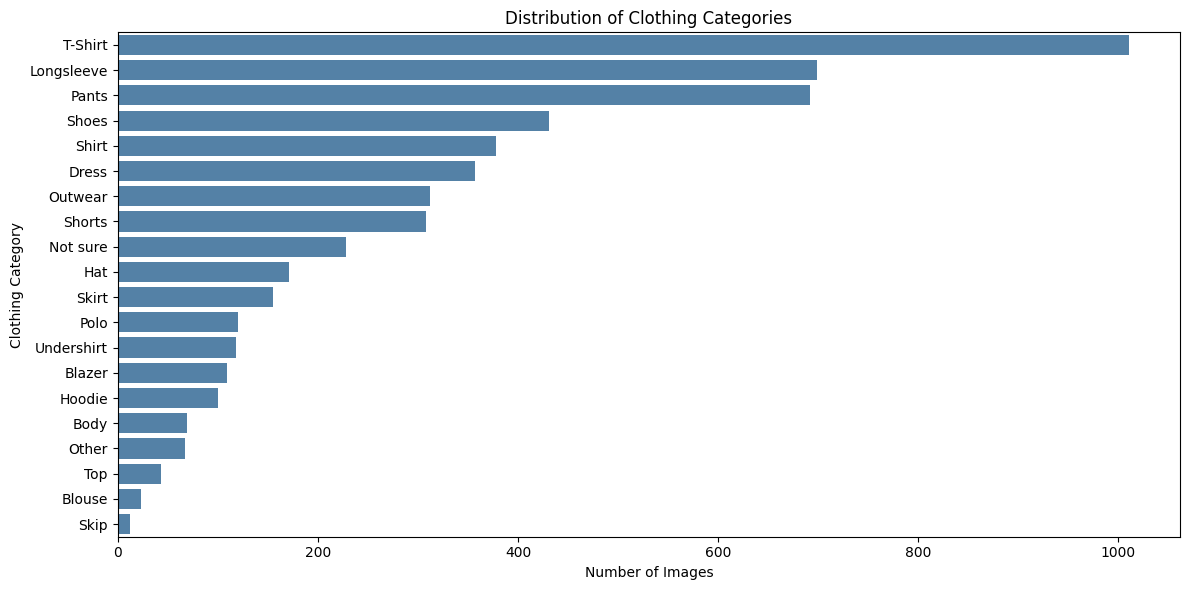

Number of Categories: 20

Category Counts:
label
T-Shirt       1011
Longsleeve     699
Pants          692
Shoes          431
Shirt          378
Dress          357
Outwear        312
Shorts         308
Not sure       228
Hat            171
Skirt          155
Polo           120
Undershirt     118
Blazer         109
Hoodie         100
Body            69
Other           67
Top             43
Blouse          23
Skip            12
Name: count, dtype: int64


In [5]:
# Clothing category distribution
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y='label',
    order=df['label'].value_counts().index,
    color='steelblue'
)

plt.title('Distribution of Clothing Categories')
plt.xlabel('Number of Images')
plt.ylabel('Clothing Category')
plt.tight_layout()
plt.show()

print("Number of Categories:", df['label'].nunique())
print("\nCategory Counts:")
print(df['label'].value_counts())


T-Shirt is the most frequent category with 1,011 images (18.7% of the dataset).



Longsleeve (699) and Pants (692) are the next most frequent categories.



Categories such as Blouse (23), Top (43), Body (69) and Hoodie (100) have relatively few images.



The dataset contains uncertain or non-specific labels: Not sure (228), Other (67) and Skip (12).



There is significant class imbalance. The largest category has approximately 44 times as many images as the smallest clothing category, Blouse.

In [6]:
# Remove ambiguous categories
exclude_labels = ['Not sure', 'Other', 'Skip']

df_clean = df[~df['label'].isin(exclude_labels)].copy()

df_clean.reset_index(drop=True, inplace=True)

print("Original Dataset:", df.shape)
print("Cleaned Dataset:", df_clean.shape)

print("\nNumber of Clothing Categories:")
print(df_clean['label'].nunique())

print("\nUpdated Class Distribution:")
print(df_clean['label'].value_counts())


Original Dataset: (5403, 4)
Cleaned Dataset: (5096, 4)

Number of Clothing Categories:
17

Updated Class Distribution:
label
T-Shirt       1011
Longsleeve     699
Pants          692
Shoes          431
Shirt          378
Dress          357
Outwear        312
Shorts         308
Hat            171
Skirt          155
Polo           120
Undershirt     118
Blazer         109
Hoodie         100
Body            69
Top             43
Blouse          23
Name: count, dtype: int64


Removed- Not sure, Other and Skip, since they do not represent clearly defined clothing types.

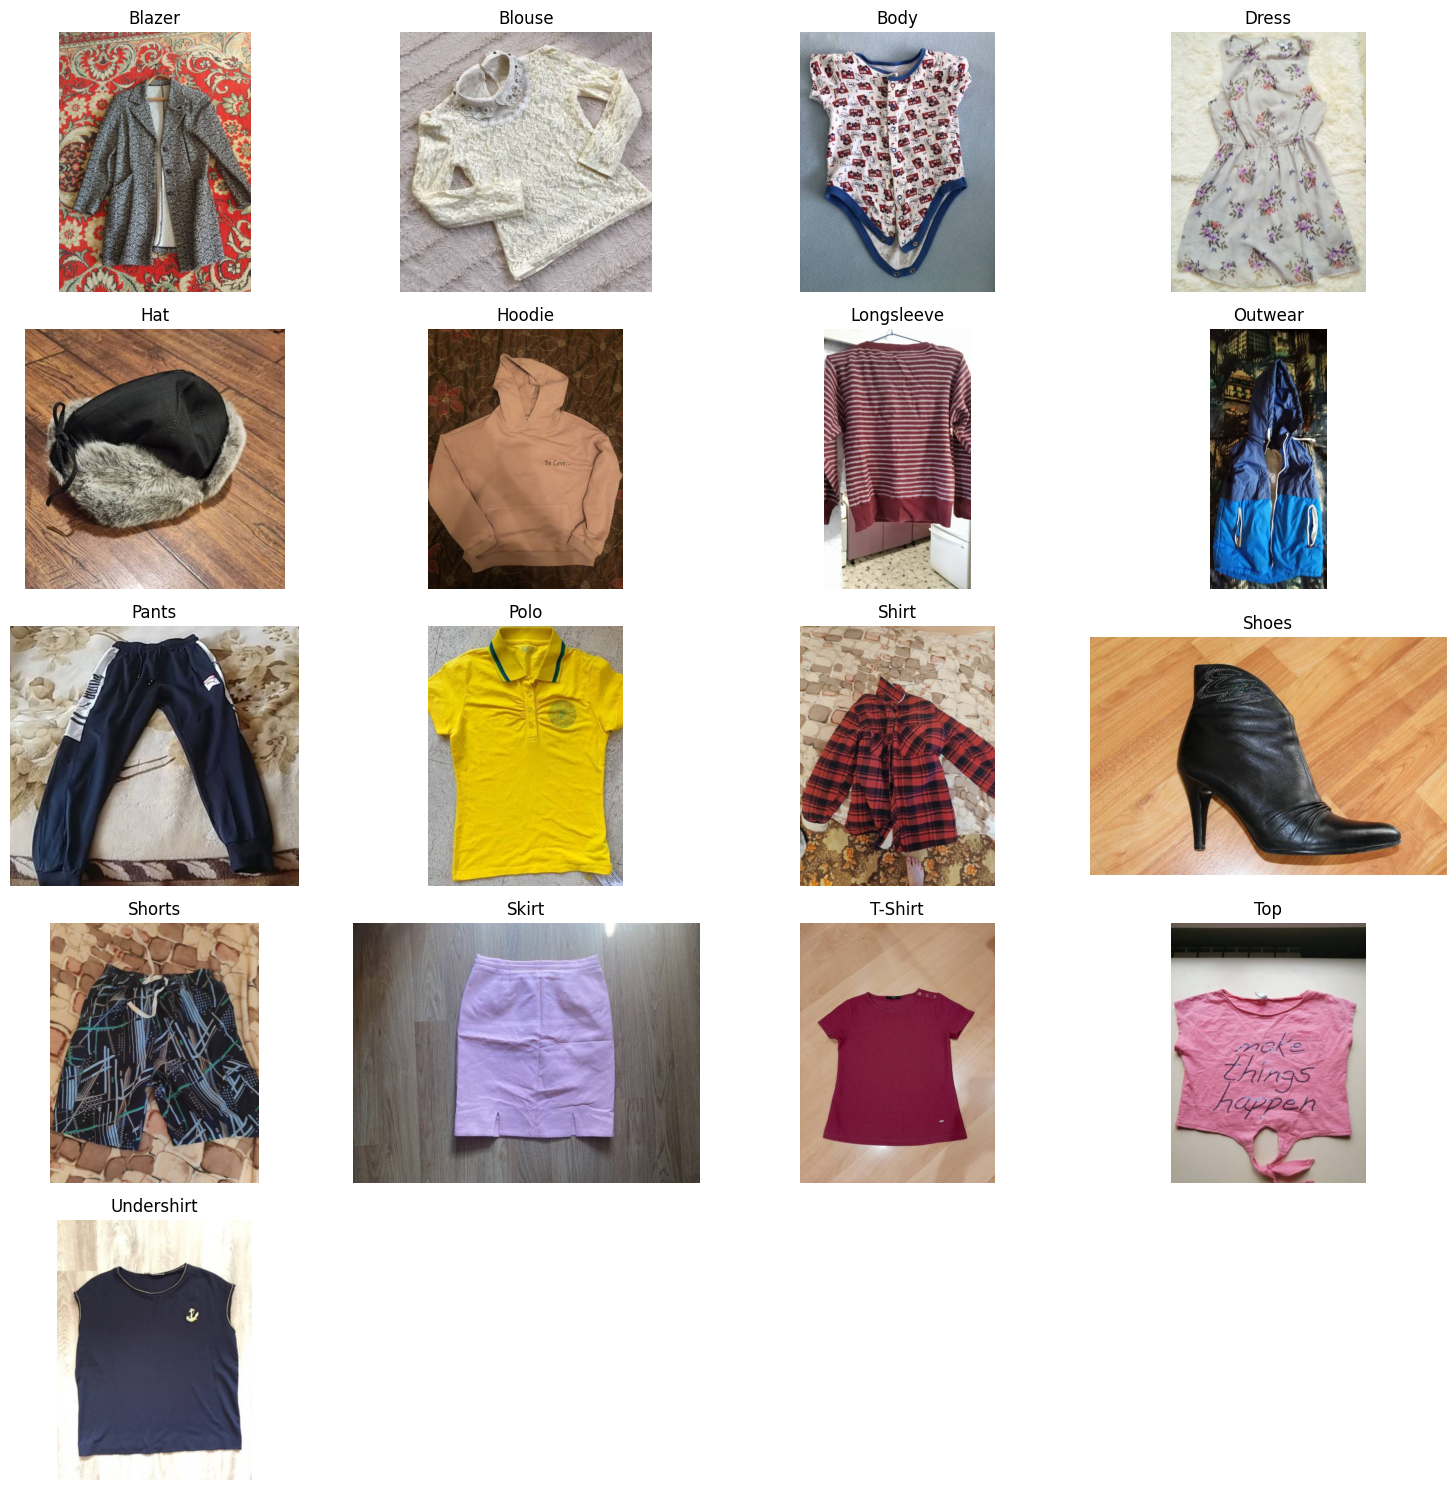

In [7]:
#visualize clothing images
import os
import matplotlib.pyplot as plt
from PIL import Image

image_dir = '/content/images_compressed'

# Display one image from each clothing category
categories = sorted(df_clean['label'].unique())

plt.figure(figsize=(15, 15))

for i, category in enumerate(categories):
    sample = df_clean[df_clean['label'] == category].iloc[0]
    image_id = sample['image']

    image_path = os.path.join(image_dir, image_id + '.jpg')

    plt.subplot(5, 4, i + 1)

    if os.path.exists(image_path):
        img = Image.open(image_path).convert('RGB')
        plt.imshow(img)
    else:
        plt.text(0.5, 0.5, 'Image Not Found',
                 ha='center', va='center')

    plt.title(category)
    plt.axis('off')

plt.tight_layout()
plt.show()


In [9]:
#Check image dimensions and corrupted images
from PIL import Image
from collections import Counter
import os

image_dir = '/content/images_compressed'

image_sizes = []
valid_images = []
invalid_images = []

for image_id in df_clean['image']:
    image_path = os.path.join(
        image_dir, image_id + '.jpg'
    )

    try:
        with Image.open(image_path) as img:
            img.verify()

        with Image.open(image_path) as img:
            image_sizes.append(img.size)

        valid_images.append(image_id)

    except Exception:
        invalid_images.append(image_id)

print("Valid Images:", len(valid_images))
print("Missing/Corrupted Images:", len(invalid_images))

print("\nMost Common Image Dimensions:")
print(Counter(image_sizes).most_common(10))


Valid Images: 5096
Missing/Corrupted Images: 0

Most Common Image Dimensions:
[((400, 533), 2287), ((400, 534), 990), ((533, 400), 344), ((400, 711), 245), ((534, 400), 151), ((400, 400), 124), ((711, 400), 76), ((400, 532), 37), ((400, 712), 22), ((400, 710), 13)]


In [10]:
#Create image paths and split the dataset
from sklearn.model_selection import train_test_split
import os

# Create full image paths
df_clean['image_path'] = df_clean['image'].apply(
    lambda x: os.path.join(
        '/content/images_compressed', x + '.jpg'
    )
)

# First split: 70% training, 30% remaining
train_df, temp_df = train_test_split(
    df_clean,
    test_size=0.30,
    random_state=42,
    stratify=df_clean['label']
)

# Second split: 15% validation, 15% testing
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df['label']
)

print("Training Images:", len(train_df))
print("Validation Images:", len(val_df))
print("Testing Images:", len(test_df))

print("\nTotal Images:",
      len(train_df) + len(val_df) + len(test_df))


Training Images: 3567
Validation Images: 764
Testing Images: 765

Total Images: 5096


In [11]:
#Create label encoding and image-loading function
import tensorflow as tf
import numpy as np

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Create consistent label mapping
class_names = sorted(df_clean['label'].unique())

label_to_index = {
    label: idx for idx, label in enumerate(class_names)
}

NUM_CLASSES = len(class_names)

print("Number of Classes:", NUM_CLASSES)
print("Class Mapping:", label_to_index)

# Convert labels into numeric values
for data in [train_df, val_df, test_df]:
    data['label_encoded'] = (
        data['label'].map(label_to_index)
    )

# Image loading function
def load_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)

    return image, label


Number of Classes: 17
Class Mapping: {'Blazer': 0, 'Blouse': 1, 'Body': 2, 'Dress': 3, 'Hat': 4, 'Hoodie': 5, 'Longsleeve': 6, 'Outwear': 7, 'Pants': 8, 'Polo': 9, 'Shirt': 10, 'Shoes': 11, 'Shorts': 12, 'Skirt': 13, 'T-Shirt': 14, 'Top': 15, 'Undershirt': 16}


In [12]:
#Create TensorFlow datasets
AUTOTUNE = tf.data.AUTOTUNE

def create_dataset(dataframe, training=False):

    paths = dataframe['image_path'].values
    labels = dataframe['label_encoded'].values

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(AUTOTUNE)

    return dataset

train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("Training Batches:", len(train_ds))
print("Validation Batches:", len(val_ds))
print("Testing Batches:", len(test_ds))


Training Batches: 112
Validation Batches: 24
Testing Batches: 24


In [13]:
#Verify image shapes
for images, labels in train_ds.take(1):

    print("Image Batch Shape:", images.shape)
    print("Label Batch Shape:", labels.shape)

    print("Minimum Pixel Value:",
          tf.reduce_min(images).numpy())

    print("Maximum Pixel Value:",
          tf.reduce_max(images).numpy())


Image Batch Shape: (32, 224, 224, 3)
Label Batch Shape: (32,)
Minimum Pixel Value: 0.0
Maximum Pixel Value: 255.0


All images were resized to 224 × 224 pixels with three RGB color channels.

The 17 clothing categories were encoded into integer labels ranging from 0 to 16.

A batch size of 32 was used for efficient model training.

TensorFlow's tf.data pipeline was used for image loading, batching and prefetching.

The training dataset was shuffled to randomize the order of images during training.

In [14]:
#Build the custom CNN

In [15]:
from tensorflow.keras import layers, models

tf.keras.backend.clear_session()

custom_cnn = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    # Normalize pixel values
    layers.Rescaling(1./255),

    # First convolutional block
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Second convolutional block
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Third convolutional block
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Classification layers
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    # Output layer
    layers.Dense(NUM_CLASSES, activation='softmax')
])

custom_cnn.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 17)             │         2,193 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,953 (437.32 KB)

 Trainable params: 111,953 (437.32 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
#Compile and train Model 1
custom_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Custom CNN compiled successfully!")


Custom CNN compiled successfully!


In [17]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True
)

history_custom = custom_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stopping]
)


Epoch 1/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 25s 135ms/step - accuracy: 0.1741 - loss: 2.5643 - val_accuracy: 0.1976 - val_loss: 2.4956
Epoch 2/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 7s 61ms/step - accuracy: 0.1873 - loss: 2.5186 - val_accuracy: 0.1976 - val_loss: 2.5081
Epoch 3/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 7s 58ms/step - accuracy: 0.1929 - loss: 2.4968 - val_accuracy: 0.1976 - val_loss: 2.4777
Epoch 4/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 10s 59ms/step - accuracy: 0.1915 - loss: 2.4802 - val_accuracy: 0.2120 - val_loss: 2.4769
Epoch 5/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 7s 58ms/step - accuracy: 0.1979 - loss: 2.4709 - val_accuracy: 0.2304 - val_loss: 2.4383
Epoch 6/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 7s 61ms/step - accuracy: 0.2066 - loss: 2.4499 - val_accuracy: 0.2081 - val_loss: 2.4316
Epoch 7/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 7s 58ms/step - accuracy: 0.2105 - loss: 2.4371 - val_accuracy: 0.2186 - val_loss: 2.4116
Epoch 8/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 7s 59ms/step - accuracy: 0.2033 - loss: 2.4247 - val_a

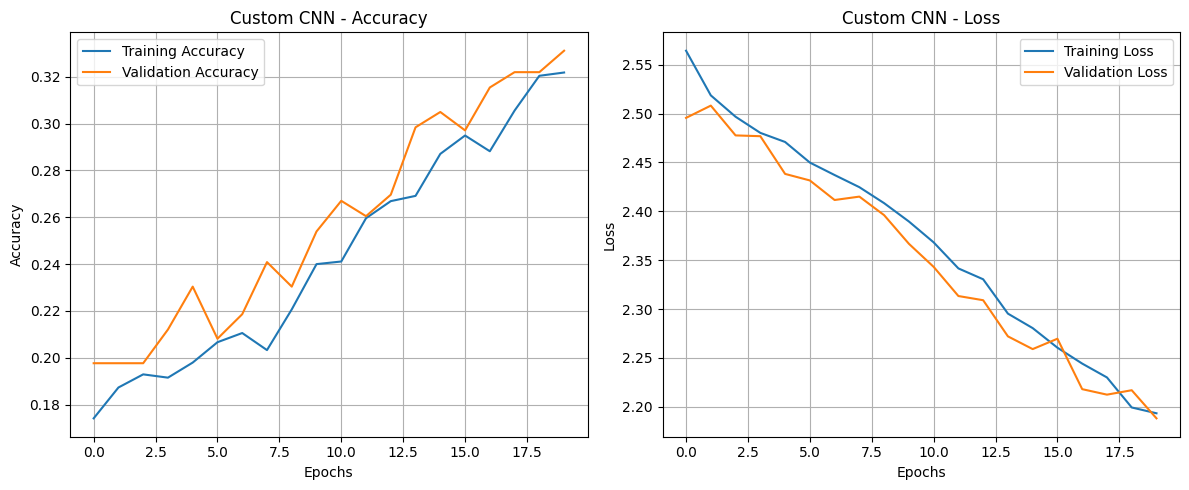

In [18]:
#Plot training and validation accuracy/loss
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history_custom.history['accuracy'],
         label='Training Accuracy')
plt.plot(history_custom.history['val_accuracy'],
         label='Validation Accuracy')

plt.title('Custom CNN - Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1, 2, 2)
plt.plot(history_custom.history['loss'],
         label='Training Loss')
plt.plot(history_custom.history['val_loss'],
         label='Validation Loss')

plt.title('Custom CNN - Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


Accuracy curve
- Training accuracy increased from approximately 17.5% to 32.18%.
- Validation accuracy increased from approximately 19.7% to 33.12%.
- Both curves show an upward trend throughout training.
- Training and validation accuracy remain close, indicating no obvious overfitting.
2. Loss curve
- Training loss decreased from approximately 2.56 to 2.19.
- Validation loss decreased from approximately 2.49 to 2.19.
- Both loss curves show a consistent downward trend, with minor fluctuations.
- Since the losses were still decreasing near the final epoch, the model may benefit from further training or architectural improvements.

In [19]:
#Evaluate test accuracy and loss
test_loss_custom, test_accuracy_custom = custom_cnn.evaluate(
    test_ds,
    verbose=1
)

print(f"Test Accuracy: {test_accuracy_custom * 100:.2f}%")
print(f"Test Loss: {test_loss_custom:.4f}")

24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 110ms/step - accuracy: 0.3176 - loss: 2.2192
Test Accuracy: 31.76%
Test Loss: 2.2192


In [20]:
#Generate classification report
import numpy as np
from sklearn.metrics import classification_report

# Actual labels
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

# Model predictions
y_pred_probs = custom_cnn.predict(test_ds)
y_pred = np.argmax(y_pred_probs, axis=1)

print(classification_report(
    y_true,
    y_pred,
    labels=range(NUM_CLASSES),
    target_names=class_names,
    zero_division=0
))

24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 61ms/step
              precision    recall  f1-score   support

      Blazer       0.00      0.00      0.00        16
      Blouse       0.00      0.00      0.00         3
        Body       0.00      0.00      0.00        10
       Dress       0.20      0.09      0.13        54
         Hat       0.62      0.19      0.29        26
      Hoodie       0.00      0.00      0.00        15
  Longsleeve       0.50      0.03      0.05       105
     Outwear       0.29      0.04      0.07        47
       Pants       0.36      0.63      0.46       104
        Polo       0.00      0.00      0.00        18
       Shirt       0.40      0.33      0.37        57
       Shoes       0.33      0.28      0.30        65
      Shorts       0.00      0.00      0.00        46
       Skirt       0.00      0.00      0.00        24
     T-Shirt       0.29      0.82      0.42       152
         Top       0.00      0.00      0.00         6
  Undershirt       0.00      0.00      0.

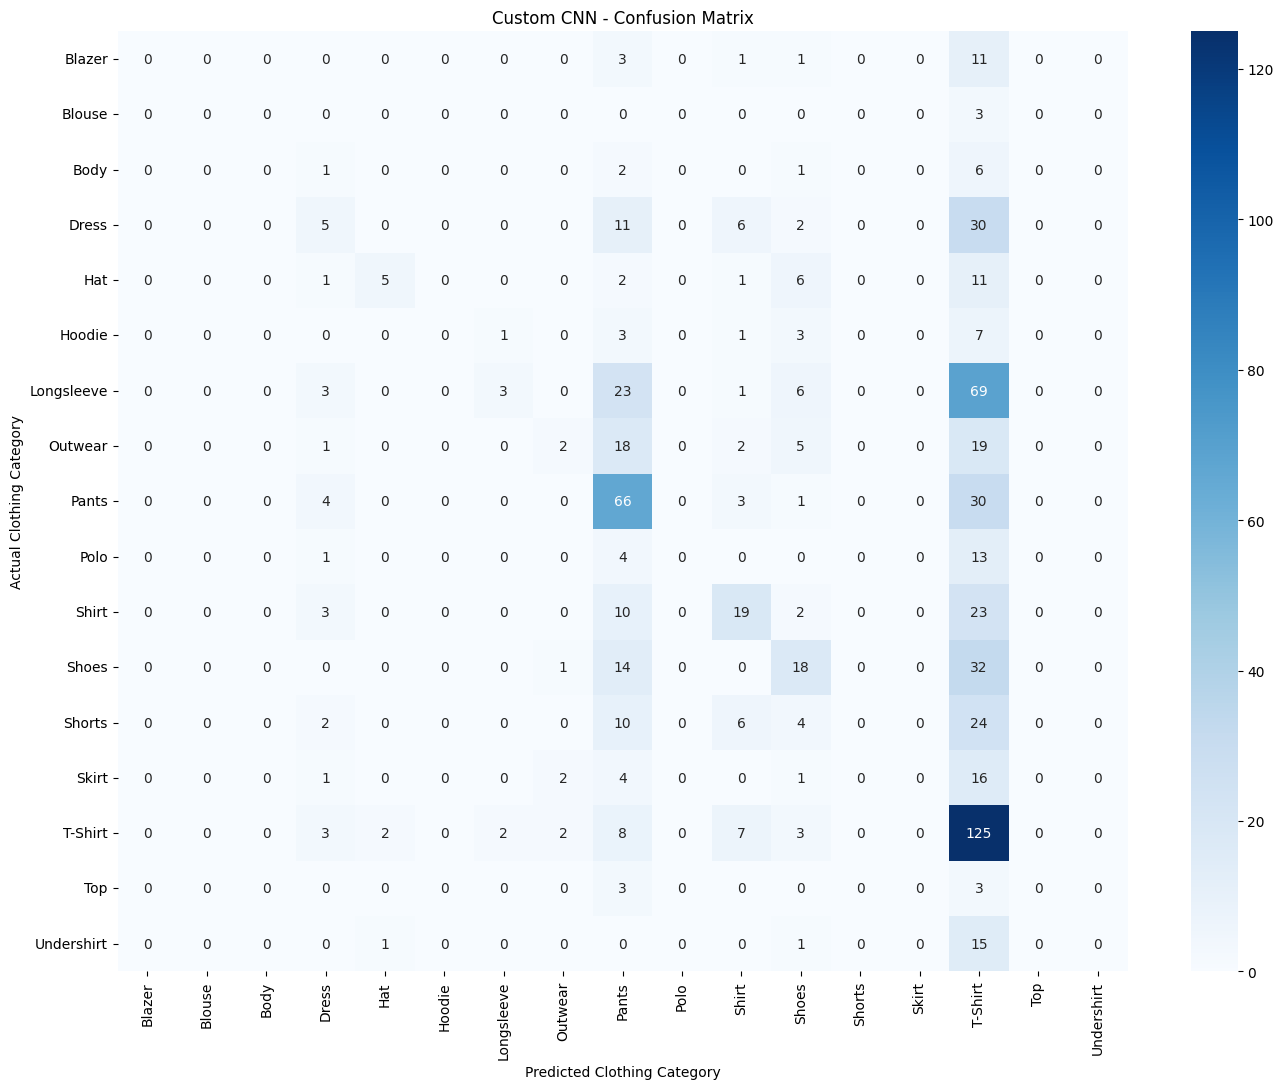

In [21]:
#Confusion matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(NUM_CLASSES)
)

plt.figure(figsize=(14, 11))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title('Custom CNN - Confusion Matrix')
plt.xlabel('Predicted Clothing Category')
plt.ylabel('Actual Clothing Category')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


The model correctly classified 125 out of 152 T-Shirt images.
It correctly classified 66 out of 104 Pants images.
It incorrectly classified 69 Longsleeve images as T-Shirt.
It incorrectly classified 30 Dress images as T-Shirt.
It incorrectly classified 32 Shoes images as T-Shirt.
It failed to correctly identify several minority categories, including Blouse, Hoodie, Shorts and Skirt.

Although training and validation accuracy are close, the low macro F1-score and confusion matrix indicate poor classification performance across the 17 classes. Class imbalance is likely contributing, alongside limitations in the learned visual features.

Model 2: Build pretrained ResNet50

In [22]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

# Load pretrained ResNet50
base_model = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
base_model.trainable = False

# Build ResNet50 classification model
inputs = layers.Input(shape=(224, 224, 3))

# ResNet50-specific preprocessing
x = layers.Lambda(preprocess_input)(inputs)

# Extract pretrained features
x = base_model(x, training=False)

# Classification layers
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.5)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation='softmax'
)(x)

resnet_model = models.Model(inputs, outputs)

resnet_model.summary()


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 17)             │         2,193 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,852,177 (90.99 MB)

 Trainable params: 264,465 (1.01 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [23]:
#Compile ResNet50
resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("ResNet50 compiled successfully!")

ResNet50 compiled successfully!


In [24]:
#Train ResNet50
from tensorflow.keras.callbacks import EarlyStopping

early_stopping_resnet = EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True
)

history_resnet = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stopping_resnet]
)


Epoch 1/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 36s 218ms/step - accuracy: 0.3109 - loss: 2.3920 - val_accuracy: 0.5262 - val_loss: 1.6805
Epoch 2/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - accuracy: 0.4954 - loss: 1.7245 - val_accuracy: 0.6217 - val_loss: 1.3596
Epoch 3/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - accuracy: 0.5831 - loss: 1.4352 - val_accuracy: 0.6767 - val_loss: 1.1650
Epoch 4/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 13s 113ms/step - accuracy: 0.6184 - loss: 1.2612 - val_accuracy: 0.6976 - val_loss: 1.0495
Epoch 5/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 12s 109ms/step - accuracy: 0.6731 - loss: 1.1127 - val_accuracy: 0.7264 - val_loss: 0.9475
Epoch 6/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 12s 111ms/step - accuracy: 0.7051 - loss: 1.0131 - val_accuracy: 0.7435 - val_loss: 0.8812
Epoch 7/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 13s 113ms/step - accuracy: 0.7051 - loss: 0.9485 - val_accuracy: 0.7500 - val_loss: 0.8304
Epoch 8/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 13s 114ms/step - accuracy: 0.7429 - loss: 0

In [25]:
#ResNet50 improved validation accuracy by 45.28 percentage points compared with the custom CNN.

Training accuracy increased steadily from 31.09% to 81.38%.
Validation accuracy increased from 52.62% to 78.40%.
Both training and validation loss decreased substantially.
The final training-validation accuracy gap is only 2.98 percentage points.
There is no strong evidence of severe overfitting, although the training accuracy is slightly higher than validation accuracy.
Validation accuracy peaked at 79.45% in epoch 14, while validation loss was lowest at epoch 14 (0.6606).

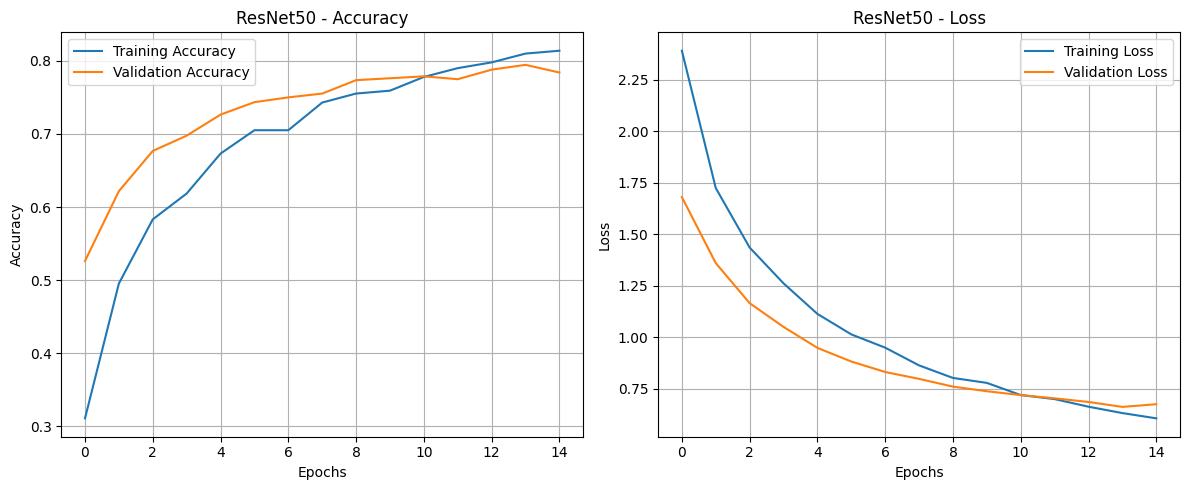

In [26]:
#Plot ResNet50 accuracy and loss curves
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history_resnet.history['accuracy'],
         label='Training Accuracy')
plt.plot(history_resnet.history['val_accuracy'],
         label='Validation Accuracy')

plt.title('ResNet50 - Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1, 2, 2)
plt.plot(history_resnet.history['loss'],
         label='Training Loss')
plt.plot(history_resnet.history['val_loss'],
         label='Validation Loss')

plt.title('ResNet50 - Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [27]:
#Evaluate ResNet50 on test data
test_loss_resnet, test_accuracy_resnet = resnet_model.evaluate(
    test_ds,
    verbose=1
)

print(f"ResNet50 Test Accuracy: {test_accuracy_resnet * 100:.2f}%")
print(f"ResNet50 Test Loss: {test_loss_resnet:.4f}")


24/24 ━━━━━━━━━━━━━━━━━━━━ 6s 233ms/step - accuracy: 0.7856 - loss: 0.6700
ResNet50 Test Accuracy: 78.56%
ResNet50 Test Loss: 0.6700


Accuracy curve: Both training and validation accuracy increased steadily over 15 epochs. The curves remained relatively close, with a final gap of approximately 2.98 percentage points.

Loss curve: Training loss decreased from approximately 2.39 to 0.61, while validation loss decreased from approximately 1.68 to 0.67. Both curves show effective learning, with no major divergence.

Overfitting: There is no strong evidence of severe overfitting. The model generalizes reasonably well to the validation and test datasets.

In [28]:
#Generate ResNet50 classification report
import numpy as np
from sklearn.metrics import classification_report

# Actual test labels
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

# ResNet50 predictions
y_pred_resnet_probs = resnet_model.predict(test_ds)
y_pred_resnet = np.argmax(
    y_pred_resnet_probs, axis=1
)

# Classification report
print(classification_report(
    y_true,
    y_pred_resnet,
    labels=range(NUM_CLASSES),
    target_names=class_names,
    zero_division=0
))


24/24 ━━━━━━━━━━━━━━━━━━━━ 10s 258ms/step
              precision    recall  f1-score   support

      Blazer       0.78      0.44      0.56        16
      Blouse       0.00      0.00      0.00         3
        Body       0.86      0.60      0.71        10
       Dress       0.71      0.65      0.68        54
         Hat       0.96      0.92      0.94        26
      Hoodie       0.75      0.20      0.32        15
  Longsleeve       0.73      0.88      0.80       105
     Outwear       0.62      0.81      0.70        47
       Pants       0.95      0.92      0.94       104
        Polo       0.88      0.39      0.54        18
       Shirt       0.67      0.67      0.67        57
       Shoes       0.98      0.97      0.98        65
      Shorts       0.72      0.83      0.77        46
       Skirt       0.87      0.54      0.67        24
     T-Shirt       0.76      0.91      0.83       152
         Top       0.00      0.00      0.00         6
  Undershirt       0.50      0.12      

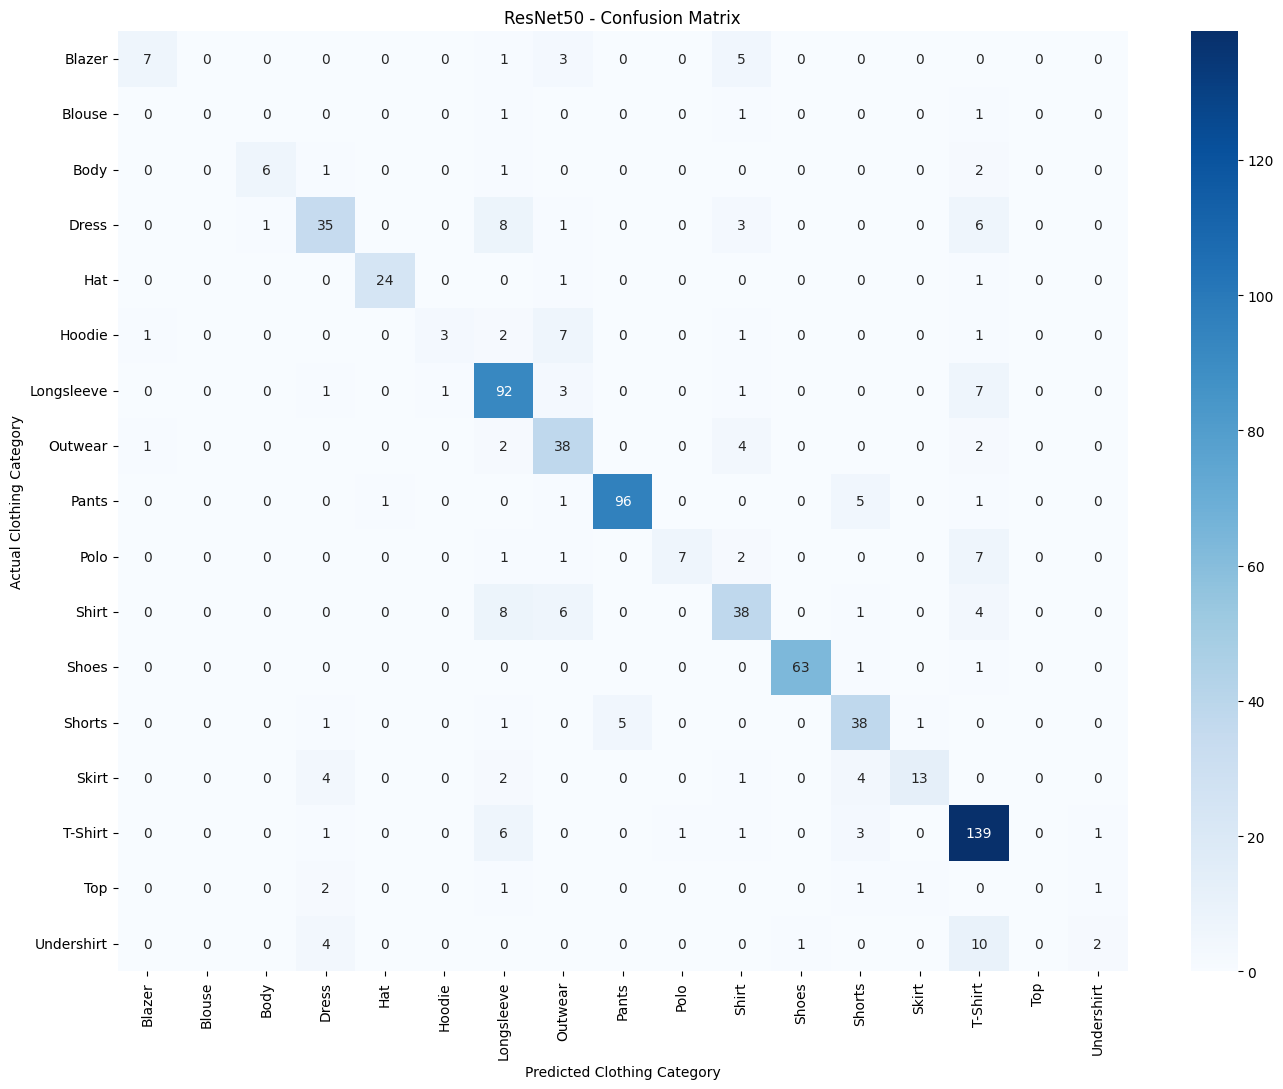

In [29]:
#Generate ResNet50 confusion matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_resnet = confusion_matrix(
    y_true,
    y_pred_resnet,
    labels=range(NUM_CLASSES)
)

plt.figure(figsize=(14, 11))

sns.heatmap(
    cm_resnet,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title('ResNet50 - Confusion Matrix')
plt.xlabel('Predicted Clothing Category')
plt.ylabel('Actual Clothing Category')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


ResNet50 recognizes Shoes, Hat and Pants particularly well.



T-Shirt recall improved from 0.82 to 0.91.



Longsleeve recall improved from 0.03 to 0.88.



Blouse and Top still have zero recall, meaning no test images from these categories were correctly classified.



The macro F1-score improved from 0.12 to 0.60, indicating substantially better performance across categories.

Model 3: ResNet50 with Data Augmentation

In [30]:
#Define data augmentation
import tensorflow as tf
from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.05, 0.05)
], name="data_augmentation")

print("Data augmentation pipeline created!")


Data augmentation pipeline created!


In [31]:
#Build ResNet50 with augmentation
from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

base_model_aug = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model_aug.trainable = False

inputs = layers.Input(shape=(224, 224, 3))

# Augmentation: active during training only
x = data_augmentation(inputs)

# ResNet50 preprocessing
x = layers.Lambda(preprocess_input)(x)

# Frozen pretrained feature extractor
x = base_model_aug(x, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.5)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation='softmax'
)(x)

resnet_aug_model = models.Model(inputs, outputs)

resnet_aug_model.summary()


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_1 (Lambda)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 17)             │         2,193 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,852,177 (90.99 MB)

 Trainable params: 264,465 (1.01 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [32]:
#Compile Model 3
resnet_aug_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("ResNet50 with augmentation compiled successfully!")


ResNet50 with augmentation compiled successfully!


In [33]:
#Train ResNet50 with Data Augmentation
from tensorflow.keras.callbacks import EarlyStopping

early_stopping_aug = EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True
)

history_resnet_aug = resnet_aug_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stopping_aug]
)


Epoch 1/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 31s 185ms/step - accuracy: 0.2829 - loss: 2.4799 - val_accuracy: 0.4843 - val_loss: 1.8383
Epoch 2/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 37s 180ms/step - accuracy: 0.4303 - loss: 1.9478 - val_accuracy: 0.5864 - val_loss: 1.4907
Epoch 3/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 19s 163ms/step - accuracy: 0.4900 - loss: 1.7266 - val_accuracy: 0.6165 - val_loss: 1.3153
Epoch 4/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 21s 165ms/step - accuracy: 0.5540 - loss: 1.5179 - val_accuracy: 0.6675 - val_loss: 1.1669
Epoch 5/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 21s 185ms/step - accuracy: 0.5943 - loss: 1.4008 - val_accuracy: 0.6767 - val_loss: 1.0886
Epoch 6/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 19s 168ms/step - accuracy: 0.6095 - loss: 1.3234 - val_accuracy: 0.6976 - val_loss: 1.0241
Epoch 7/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 19s 169ms/step - accuracy: 0.6384 - loss: 1.2452 - val_accuracy: 0.6976 - val_loss: 0.9737
Epoch 8/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 19s 172ms/step - accuracy: 0.6501 - loss: 1

Training accuracy increased from 28.29% in epoch 1 to 71.83% in epoch 15.



Validation accuracy improved from 48.43% to 74.74%.



Training loss decreased from 2.4799 to 0.8890, while validation loss decreased from 1.8383 to 0.7719.



Validation accuracy is slightly higher than training accuracy. This can happen because augmentation makes training images more challenging, while validation images remain unaugmented.



Compared with Model 2, Model 3 has 3.66 percentage points lower validation accuracy at the final epoch.



Validation loss was still decreasing at epoch 15, suggesting the augmented model might benefit from additional training.

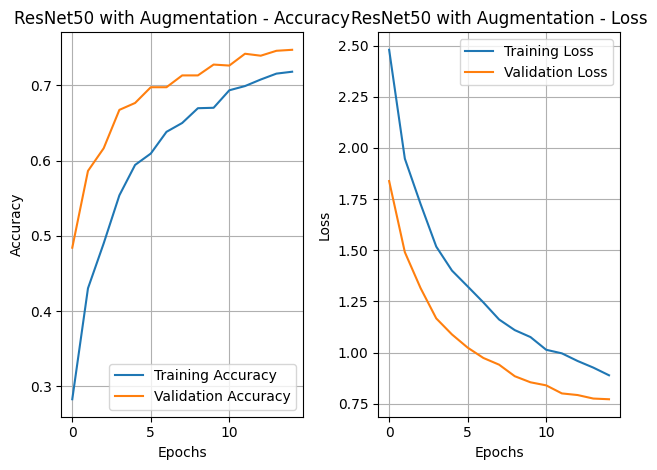

In [34]:
#Plot Model 3 accuracy and loss curves
# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history_resnet_aug.history['accuracy'],
         label='Training Accuracy')
plt.plot(history_resnet_aug.history['val_accuracy'],
         label='Validation Accuracy')

plt.title('ResNet50 with Augmentation - Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1, 2, 2)
plt.plot(history_resnet_aug.history['loss'],
         label='Training Loss')
plt.plot(history_resnet_aug.history['val_loss'],
         label='Validation Loss')

plt.title('ResNet50 with Augmentation - Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [35]:
#Evaluate Model 3 on test data
test_loss_aug, test_accuracy_aug = resnet_aug_model.evaluate(
    test_ds,
    verbose=1
)

print(f"Augmented ResNet50 Test Accuracy: {test_accuracy_aug * 100:.2f}%")
print(f"Augmented ResNet50 Test Loss: {test_loss_aug:.4f}")


24/24 ━━━━━━━━━━━━━━━━━━━━ 4s 143ms/step - accuracy: 0.7529 - loss: 0.7464
Augmented ResNet50 Test Accuracy: 75.29%
Augmented ResNet50 Test Loss: 0.7464


Both training and validation accuracy increased steadily over 15 epochs.



Both training and validation loss decreased consistently.



Validation accuracy remained higher than training accuracy, which can occur because augmented training images are more challenging.



There is no clear evidence of severe overfitting.



The validation loss was still decreasing at epoch 15, suggesting that additional training might improve performance.

In [36]:
#Generate Model 3 classification report
import numpy as np
from sklearn.metrics import classification_report

# Predictions for Model 3
y_pred_aug_probs = resnet_aug_model.predict(test_ds)

y_pred_aug = np.argmax(
    y_pred_aug_probs,
    axis=1
)

print(classification_report(
    y_true,
    y_pred_aug,
    labels=range(NUM_CLASSES),
    target_names=class_names,
    zero_division=0
))

24/24 ━━━━━━━━━━━━━━━━━━━━ 6s 192ms/step
              precision    recall  f1-score   support

      Blazer       0.44      0.50      0.47        16
      Blouse       0.00      0.00      0.00         3
        Body       1.00      0.30      0.46        10
       Dress       0.76      0.57      0.65        54
         Hat       1.00      0.88      0.94        26
      Hoodie       0.00      0.00      0.00        15
  Longsleeve       0.67      0.85      0.75       105
     Outwear       0.76      0.66      0.70        47
       Pants       0.93      0.92      0.93       104
        Polo       1.00      0.11      0.20        18
       Shirt       0.66      0.65      0.65        57
       Shoes       0.98      0.97      0.98        65
      Shorts       0.69      0.78      0.73        46
       Skirt       0.80      0.50      0.62        24
     T-Shirt       0.68      0.94      0.79       152
         Top       0.00      0.00      0.00         6
  Undershirt       0.40      0.12      0

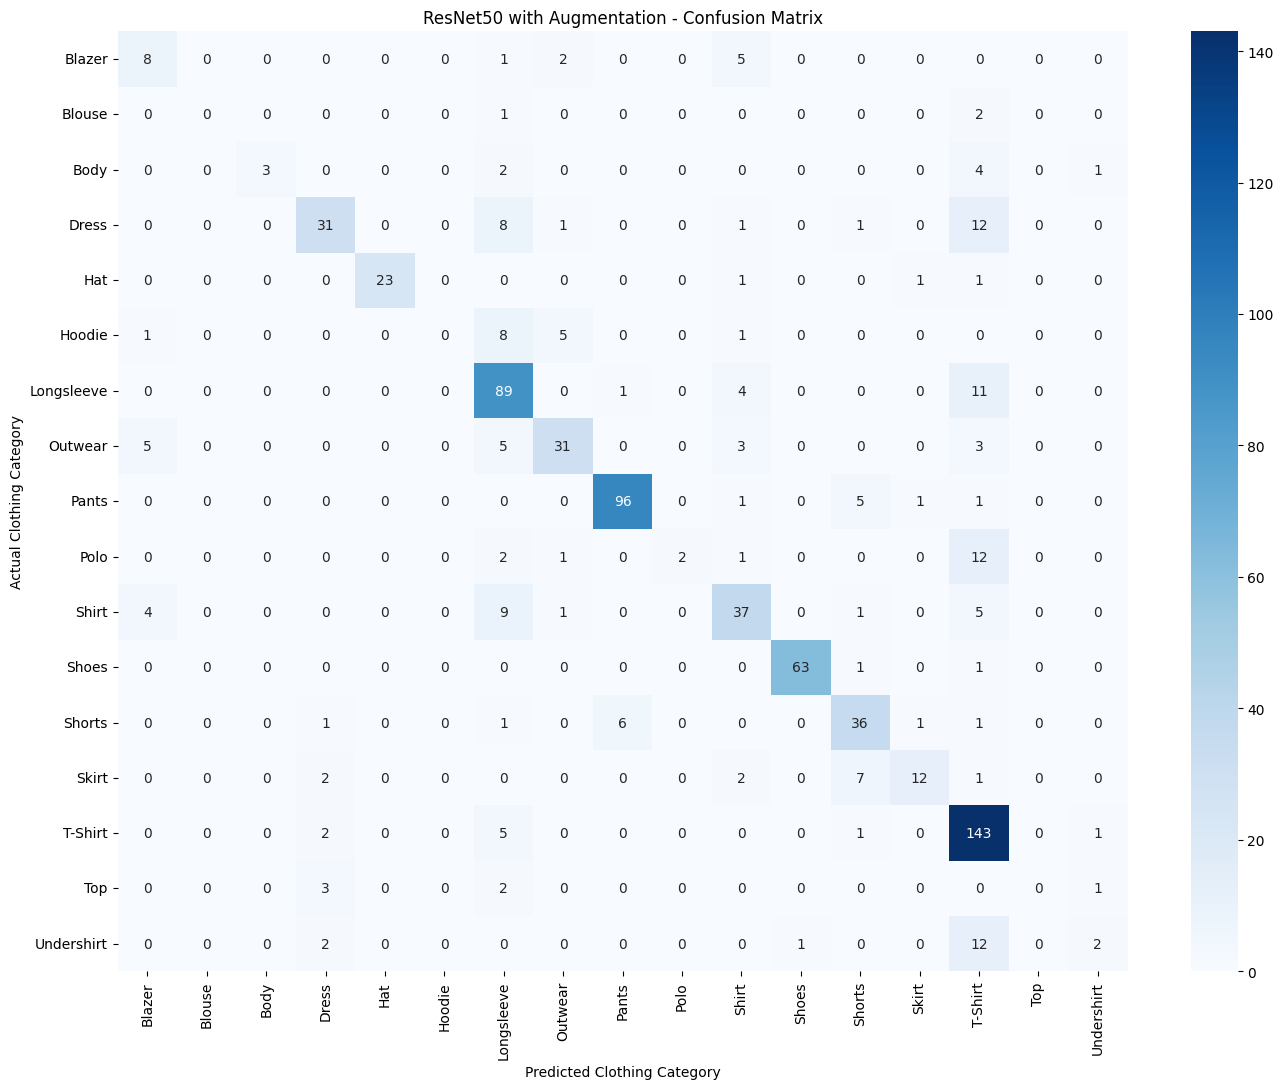

In [37]:
#Generate Model 3 confusion matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_aug = confusion_matrix(
    y_true,
    y_pred_aug,
    labels=range(NUM_CLASSES)
)

plt.figure(figsize=(14, 11))

sns.heatmap(
    cm_aug,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title('ResNet50 with Augmentation - Confusion Matrix')
plt.xlabel('Predicted Clothing Category')
plt.ylabel('Actual Clothing Category')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


The model achieved strong classification performance for Shoes, Hat, Pants and T-Shirt.

T-Shirt recall improved slightly compared with the pretrained ResNet50 model without augmentation.

Minority categories such as Blouse and Top continued to record zero recall.

Hoodie classification performance deteriorated, with zero correctly classified test images.

The macro F1-score decreased from 0.60 to 0.53 compared with Model 2.

The confusion matrix showed that misclassifications persisted between visually similar clothing categories.

Although data augmentation introduced additional training image variations, it did not improve overall testing accuracy or macro F1-score under the current training configuration.

The pretrained ResNet50 model without augmentation demonstrated better overall classification performance and more balanced class-wise results.

In [38]:
# Save original ResNet50 model
resnet_model.save('/content/resnet50_original.keras')

print("Original ResNet50 saved successfully!")


Original ResNet50 saved successfully!


In [40]:
#Run an additional experiment with class weighting or fine-tuning to see whether minority-class performance improves before deployment.

In [44]:
# Create class mapping from existing class names
class_mapping = {
    name: idx
    for idx, name in enumerate(class_names)
}

print("Class Mapping:")
print(class_mapping)


Class Mapping:
{'Blazer': 0, 'Blouse': 1, 'Body': 2, 'Dress': 3, 'Hat': 4, 'Hoodie': 5, 'Longsleeve': 6, 'Outwear': 7, 'Pants': 8, 'Polo': 9, 'Shirt': 10, 'Shoes': 11, 'Shorts': 12, 'Skirt': 13, 'T-Shirt': 14, 'Top': 15, 'Undershirt': 16}


In [45]:
#Calculate class weights
import numpy as np
import pandas as pd
from sklearn.utils.class_weight import compute_class_weight

# Convert training labels to numerical values
train_labels = train_df['label'].map(class_mapping).to_numpy()

# Check for unmapped labels
print("Unmapped Labels:", pd.isna(train_labels).sum())

# Calculate class weights
weights = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(NUM_CLASSES),
    y=train_labels.astype(int)
)

class_weights = {
    i: float(weight)
    for i, weight in enumerate(weights)
}

weights_df = pd.DataFrame({
    'Clothing Category': class_names,
    'Class Weight': weights
})

display(weights_df.sort_values(
    by='Class Weight',
    ascending=False
))


Unmapped Labels: 0


,Clothing Category,Class Weight
1,Blouse,13.113971
15,Top,6.994118
2,Body,4.371324
5,Hoodie,2.997479
0,Blazer,2.760836
16,Undershirt,2.527994
9,Polo,2.497899
13,Skirt,1.942810
4,Hat,1.748529
12,Shorts,0.971405


In [46]:
#Build Model 4 – ResNet50 with Class Weights
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

# Fresh pretrained ResNet50
base_model_weighted = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
base_model_weighted.trainable = False

# Build weighted ResNet50
inputs = layers.Input(shape=(224, 224, 3))

x = layers.Lambda(preprocess_input)(inputs)

x = base_model_weighted(x, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.5)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation='softmax'
)(x)

resnet_weighted_model = models.Model(
    inputs,
    outputs
)

resnet_weighted_model.summary()


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_2 (Lambda)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 17)             │         2,193 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,852,177 (90.99 MB)

 Trainable params: 264,465 (1.01 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [47]:
#compile model 4
resnet_weighted_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Class-weighted ResNet50 compiled successfully!")


Class-weighted ResNet50 compiled successfully!


In [48]:
#Train ResNet50 with Class Weights
from tensorflow.keras.callbacks import EarlyStopping

early_stopping_weighted = EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True
)

history_weighted = resnet_weighted_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    class_weight=class_weights,
    callbacks=[early_stopping_weighted]
)


Epoch 1/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 32s 197ms/step - accuracy: 0.1550 - loss: 2.8805 - val_accuracy: 0.3364 - val_loss: 2.2810
Epoch 2/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 12s 111ms/step - accuracy: 0.3003 - loss: 2.3665 - val_accuracy: 0.4372 - val_loss: 1.9776
Epoch 3/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 13s 112ms/step - accuracy: 0.3849 - loss: 2.0463 - val_accuracy: 0.5249 - val_loss: 1.7278
Epoch 4/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 21s 112ms/step - accuracy: 0.4446 - loss: 1.8194 - val_accuracy: 0.6008 - val_loss: 1.4733
Epoch 5/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 12s 110ms/step - accuracy: 0.5071 - loss: 1.5864 - val_accuracy: 0.6322 - val_loss: 1.3693
Epoch 6/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 13s 111ms/step - accuracy: 0.5335 - loss: 1.4368 - val_accuracy: 0.6702 - val_loss: 1.2544
Epoch 7/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 13s 113ms/step - accuracy: 0.5899 - loss: 1.3099 - val_accuracy: 0.6715 - val_loss: 1.1869
Epoch 8/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 13s 114ms/step - accuracy: 0.5941 - loss: 1

Training accuracy increased from 15.50% to 72.67%.



Validation accuracy increased from 33.64% to 74.48%.



Both training and validation loss decreased steadily.



Validation accuracy remained slightly higher than training accuracy at the final epoch.



Class weighting resulted in a 3.92 percentage-point reduction in final validation accuracy compared with the original ResNet50.



Validation loss was still decreasing at epoch 15, suggesting that additional training might improve performance.

In [49]:
#Evaluate Model 4 on test data
# Evaluate class-weighted ResNet50

test_loss_weighted, test_accuracy_weighted = (
    resnet_weighted_model.evaluate(
        test_ds,
        verbose=1
    )
)

print(
    f"Weighted ResNet50 Test Accuracy: "
    f"{test_accuracy_weighted * 100:.2f}%"
)

print(
    f"Weighted ResNet50 Test Loss: "
    f"{test_loss_weighted:.4f}"
)


24/24 ━━━━━━━━━━━━━━━━━━━━ 4s 183ms/step - accuracy: 0.7634 - loss: 0.8322
Weighted ResNet50 Test Accuracy: 76.34%
Weighted ResNet50 Test Loss: 0.8322


In [50]:
#Generate classification report
import numpy as np
from sklearn.metrics import classification_report

# Predict using weighted ResNet50
y_pred_weighted_probs = resnet_weighted_model.predict(
    test_ds
)

y_pred_weighted = np.argmax(
    y_pred_weighted_probs,
    axis=1
)

print(classification_report(
    y_true,
    y_pred_weighted,
    labels=range(NUM_CLASSES),
    target_names=class_names,
    zero_division=0
))


24/24 ━━━━━━━━━━━━━━━━━━━━ 10s 251ms/step
              precision    recall  f1-score   support

      Blazer       0.57      0.75      0.65        16
      Blouse       0.00      0.00      0.00         3
        Body       0.59      1.00      0.74        10
       Dress       0.73      0.67      0.70        54
         Hat       0.88      0.88      0.88        26
      Hoodie       0.33      0.60      0.43        15
  Longsleeve       0.81      0.75      0.78       105
     Outwear       0.77      0.77      0.77        47
       Pants       0.96      0.88      0.92       104
        Polo       0.33      0.78      0.47        18
       Shirt       0.71      0.65      0.68        57
       Shoes       1.00      0.97      0.98        65
      Shorts       0.70      0.80      0.75        46
       Skirt       0.75      0.75      0.75        24
     T-Shirt       0.91      0.68      0.78       152
         Top       0.50      0.50      0.50         6
  Undershirt       0.41      0.65      

Class weighting improved minority-category recognition, although Blouse still has zero recall. Also, the test set contains only three Blouse images and six Top images, so those class-level results are uncertain.

The original ResNet50 remains preferable for overall accuracy, while the class-weighted ResNet50 provides better macro F1-score and macro recall.

In [53]:
#Fine-Tuned ResNet50
import tensorflow as tf
from tensorflow.keras.applications.resnet50 import preprocess_input

# Load original ResNet50 for fine-tuning
fine_tune_model = tf.keras.models.load_model(
    '/content/resnet50_original.keras',
    custom_objects={
        'preprocess_input': preprocess_input
    },
    compile=False,
    safe_mode=False
)

print("Fine-tuning model loaded successfully!")

fine_tune_model.summary()


Fine-tuning model loaded successfully!


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 17)             │         2,193 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,852,177 (90.99 MB)

 Trainable params: 264,465 (1.01 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [54]:
#Unfreeze the last 30 ResNet50 layers
import tensorflow as tf

# Access pretrained ResNet50 backbone
base_model_finetune = fine_tune_model.get_layer('resnet50')

# Enable fine-tuning
base_model_finetune.trainable = True

# Freeze all layers except the last 30
for layer in base_model_finetune.layers[:-30]:
    layer.trainable = False

# Keep BatchNormalization layers frozen
for layer in base_model_finetune.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Verify fine-tuning configuration
print("Total Backbone Layers:",
      len(base_model_finetune.layers))

print("Trainable Backbone Layers:",
      sum(layer.trainable for layer in base_model_finetune.layers))

print("Total Trainable Parameters:",
      sum(
          int(tf.size(w))
          for w in fine_tune_model.trainable_weights
      ))

print("Fine-tuning configuration completed!")


Total Backbone Layers: 175
Trainable Backbone Layers: 21
Total Trainable Parameters: 14693137
Fine-tuning configuration completed!


In [55]:
#Compile the fine-tuned ResNet50
fine_tune_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.00001
    ),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Fine-tuned ResNet50 compiled successfully!")


Fine-tuned ResNet50 compiled successfully!


In [57]:
#Train the fine-tuned ResNet50
from tensorflow.keras.callbacks import EarlyStopping

# Early stopping
early_stopping_finetune = EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True
)

# Train fine-tuned model
history_finetune = fine_tune_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stopping_finetune]
)


Epoch 1/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 16s 144ms/step - accuracy: 0.9274 - loss: 0.2190 - val_accuracy: 0.8220 - val_loss: 0.6045
Epoch 2/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 16s 140ms/step - accuracy: 0.9375 - loss: 0.1928 - val_accuracy: 0.8285 - val_loss: 0.5856
Epoch 3/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 16s 144ms/step - accuracy: 0.9551 - loss: 0.1484 - val_accuracy: 0.8285 - val_loss: 0.5714
Epoch 4/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 21s 148ms/step - accuracy: 0.9655 - loss: 0.1145 - val_accuracy: 0.8233 - val_loss: 0.6660
Epoch 5/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 16s 147ms/step - accuracy: 0.9675 - loss: 0.1018 - val_accuracy: 0.8259 - val_loss: 0.6658
Epoch 6/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 16s 147ms/step - accuracy: 0.9762 - loss: 0.0815 - val_accuracy: 0.8390 - val_loss: 0.6595
Epoch 7/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 17s 149ms/step - accuracy: 0.9823 - loss: 0.0682 - val_accuracy: 0.8312 - val_loss: 0.6741


Training accuracy increased from 92.74% to 98.23%.



Validation accuracy reached its highest value of 83.90% at epoch 6.



Validation loss was lowest at epoch 3 (0.5714).



After epoch 3, validation loss increased, while training loss continued decreasing.



The gap between training and validation accuracy suggests overfitting.

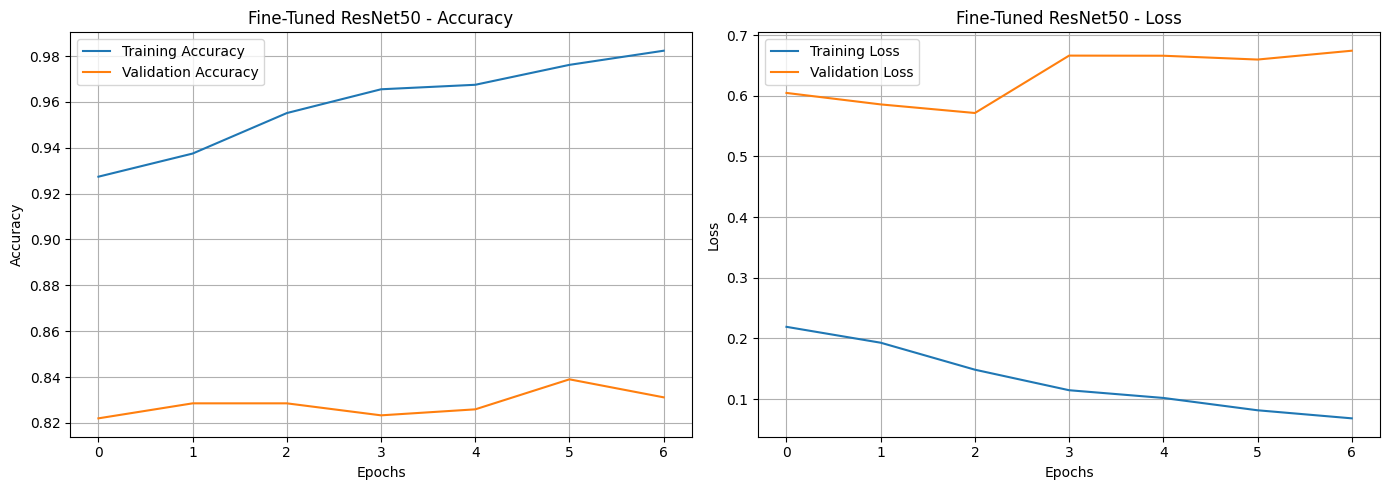

In [58]:
#Plot training and validation accuracy/loss
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history_finetune.history['accuracy'],
         label='Training Accuracy')
plt.plot(history_finetune.history['val_accuracy'],
         label='Validation Accuracy')
plt.title('Fine-Tuned ResNet50 - Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1, 2, 2)
plt.plot(history_finetune.history['loss'],
         label='Training Loss')
plt.plot(history_finetune.history['val_loss'],
         label='Validation Loss')
plt.title('Fine-Tuned ResNet50 - Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [59]:

# Evaluate fine-tuned ResNet50

test_loss_finetune, test_accuracy_finetune = (
    fine_tune_model.evaluate(
        test_ds,
        verbose=1
    )
)

print(
    f"Fine-Tuned ResNet50 Test Accuracy: "
    f"{test_accuracy_finetune * 100:.2f}%"
)

print(
    f"Fine-Tuned ResNet50 Test Loss: "
    f"{test_loss_finetune:.4f}"
)


24/24 ━━━━━━━━━━━━━━━━━━━━ 4s 174ms/step - accuracy: 0.8261 - loss: 0.6060
Fine-Tuned ResNet50 Test Accuracy: 82.61%
Fine-Tuned ResNet50 Test Loss: 0.6060


Training accuracy increased from 92.74% to 98.23%.



Validation accuracy peaked at 83.90% in epoch 6.



Validation loss reached its minimum of 0.5714 at epoch 3, then increased.



The widening training-validation gap indicates overfitting.



Early stopping restored the weights from the epoch with the lowest validation loss.

In [60]:
#Generate classification report
import numpy as np
from sklearn.metrics import classification_report

# Predict using fine-tuned ResNet50
y_pred_finetune_probs = fine_tune_model.predict(test_ds)

y_pred_finetune = np.argmax(
    y_pred_finetune_probs,
    axis=1
)

# Generate classification report
print(classification_report(
    y_true,
    y_pred_finetune,
    labels=range(NUM_CLASSES),
    target_names=class_names,
    zero_division=0
))


24/24 ━━━━━━━━━━━━━━━━━━━━ 9s 238ms/step
              precision    recall  f1-score   support

      Blazer       0.67      0.62      0.65        16
      Blouse       0.00      0.00      0.00         3
        Body       0.90      0.90      0.90        10
       Dress       0.83      0.72      0.77        54
         Hat       0.93      0.96      0.94        26
      Hoodie       0.50      0.53      0.52        15
  Longsleeve       0.80      0.86      0.83       105
     Outwear       0.80      0.77      0.78        47
       Pants       0.96      0.92      0.94       104
        Polo       0.65      0.61      0.63        18
       Shirt       0.75      0.72      0.73        57
       Shoes       0.98      0.97      0.98        65
      Shorts       0.71      0.87      0.78        46
       Skirt       0.84      0.67      0.74        24
     T-Shirt       0.83      0.92      0.87       152
         Top       1.00      0.17      0.29         6
  Undershirt       0.58      0.41      0

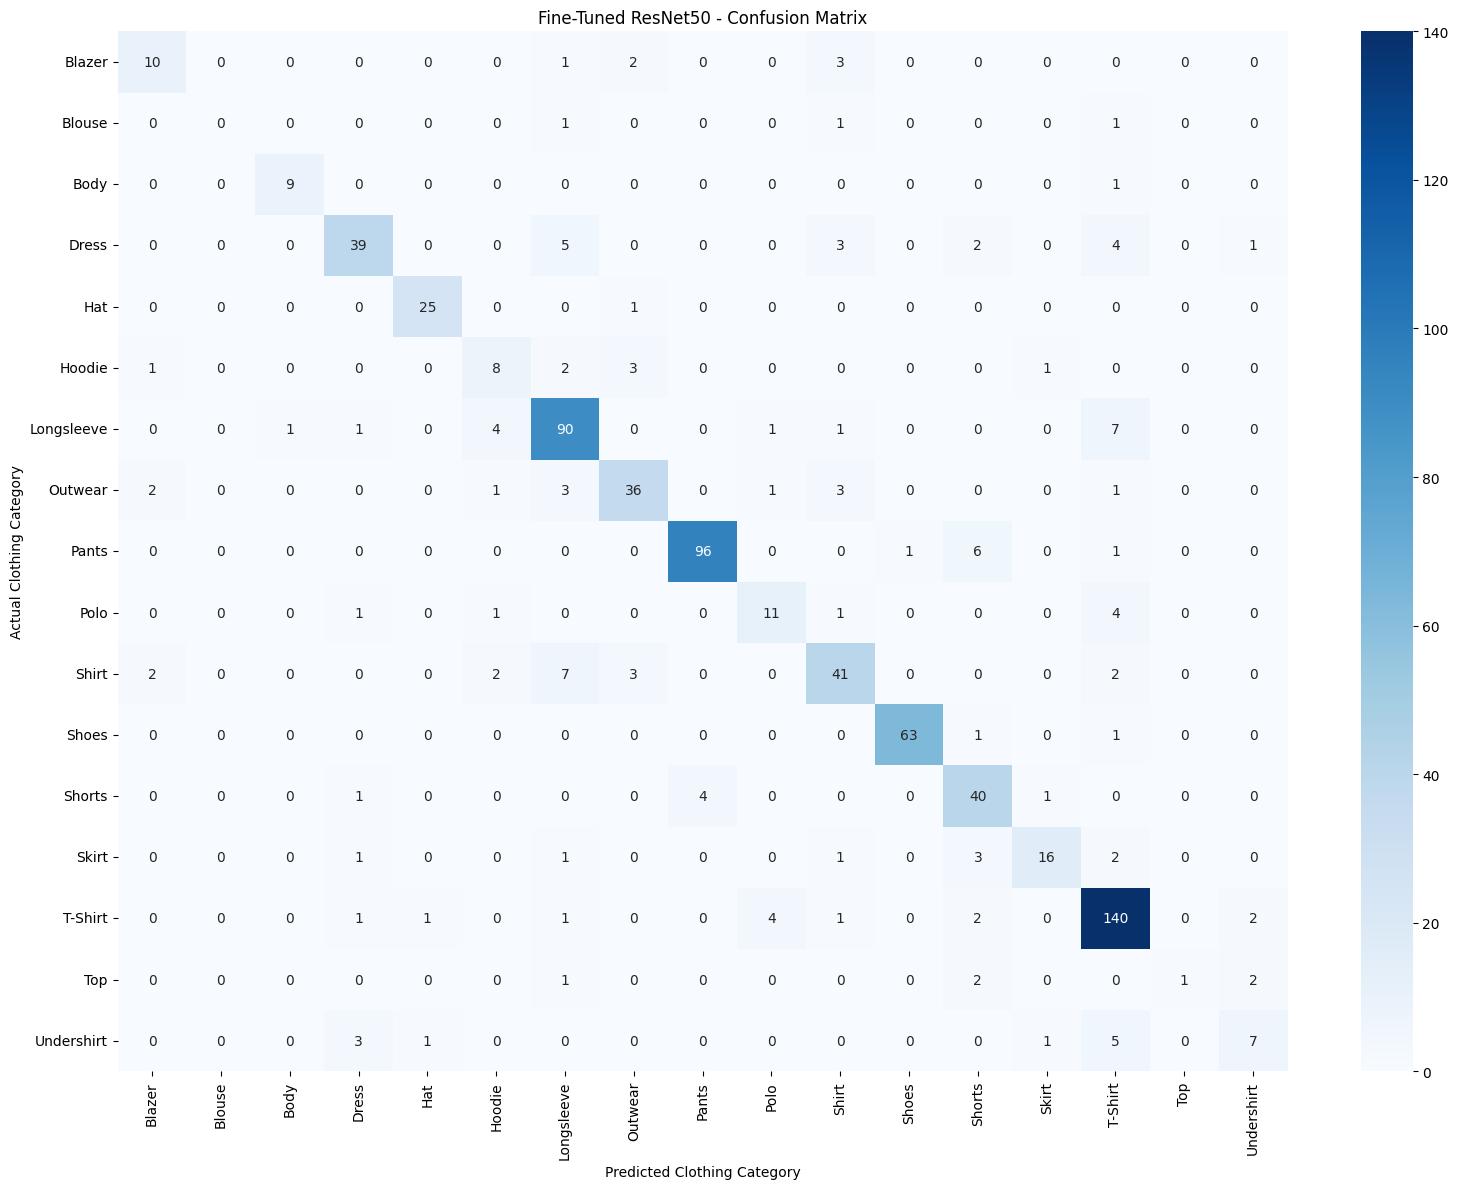

In [61]:
#Generate confusion matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_finetune = confusion_matrix(
    y_true,
    y_pred_finetune,
    labels=range(NUM_CLASSES)
)

plt.figure(figsize=(16, 12))

sns.heatmap(
    cm_finetune,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title('Fine-Tuned ResNet50 - Confusion Matrix')
plt.xlabel('Predicted Clothing Category')
plt.ylabel('Actual Clothing Category')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


Shoes, Hat, Pants and T-Shirt were classified with high recall.



Hoodie improved compared with the original ResNet50, with recall increasing from 20% to 53%.



The model still struggles with Blouse, which has only three test images.



Some confusion remains between visually similar categories, such as Shirt and Longsleeve, and Shorts and Pants.



Macro F1-score improved from 0.60 to 0.70 compared with the original ResNet50.

The results suggest that fine-tuning helped the model learn more clothing-specific visual features.

In [62]:
# Save fine-tuned ResNet50 model
fine_tune_model.save(
    '/content/resnet50_finetuned.keras'
)

print("Fine-tuned ResNet50 saved successfully!")


Fine-tuned ResNet50 saved successfully!


In [64]:
from google.colab import files

files.download('/content/resnet50_finetuned.keras')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [65]:
#Final model comparison
import pandas as pd

# Final comparison of all 5 models
comparison_df = pd.DataFrame({
    'Model': [
        'Custom CNN',
        'ResNet50',
        'ResNet50 + Augmentation',
        'ResNet50 + Class Weights',
        'Fine-Tuned ResNet50'
    ],

    'Training Accuracy (%)': [
        history_custom.history['accuracy'][-1] * 100,
        history_resnet.history['accuracy'][-1] * 100,
        history_resnet_aug.history['accuracy'][-1] * 100,
        history_weighted.history['accuracy'][-1] * 100,
        history_finetune.history['accuracy'][-1] * 100
    ],

    'Validation Accuracy (%)': [
        history_custom.history['val_accuracy'][-1] * 100,
        history_resnet.history['val_accuracy'][-1] * 100,
        history_resnet_aug.history['val_accuracy'][-1] * 100,
        history_weighted.history['val_accuracy'][-1] * 100,
        history_finetune.history['val_accuracy'][-1] * 100
    ],

    'Testing Accuracy (%)': [
        test_accuracy_custom * 100,
        test_accuracy_resnet * 100,
        test_accuracy_aug * 100,
        test_accuracy_weighted * 100,
        test_accuracy_finetune * 100
    ],

    'Testing Loss': [
        test_loss_custom,
        test_loss_resnet,
        test_loss_aug,
        test_loss_weighted,
        test_loss_finetune
    ],

    'Macro F1 Score': [
        0.12, 0.60, 0.53, 0.66, 0.70
    ]
})

display(comparison_df.round(2))

,Model,Training Accuracy (%),Validation Accuracy (%),Testing Accuracy (%),Testing Loss,Macro F1 Score
0,Custom CNN,32.18,33.12,31.76,2.22,0.12
1,ResNet50,81.38,78.40,78.56,0.67,0.60
2,ResNet50 + Augmentation,71.83,74.74,75.29,0.75,0.53
3,ResNet50 + Class Weights,72.67,74.48,76.34,0.83,0.66
4,Fine-Tuned ResNet50,98.23,83.12,82.61,0.61,0.70


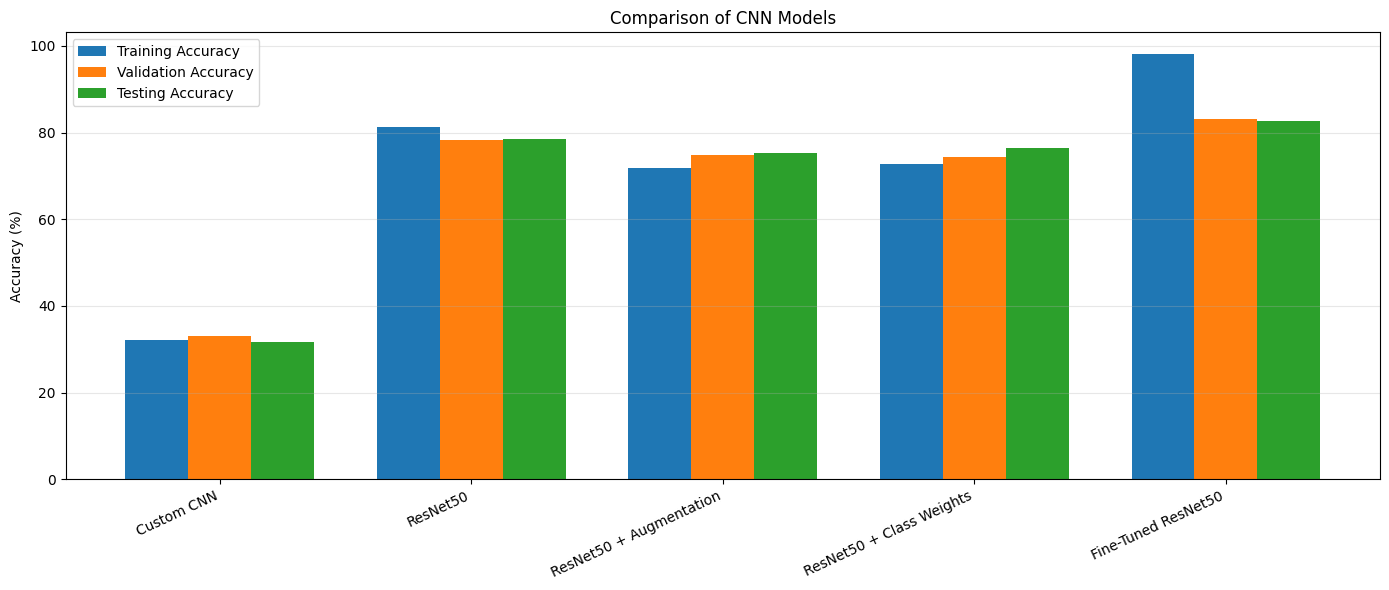

In [66]:
import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(comparison_df))
width = 0.25

plt.figure(figsize=(14, 6))

plt.bar(
    x - width,
    comparison_df['Training Accuracy (%)'],
    width,
    label='Training Accuracy'
)

plt.bar(
    x,
    comparison_df['Validation Accuracy (%)'],
    width,
    label='Validation Accuracy'
)

plt.bar(
    x + width,
    comparison_df['Testing Accuracy (%)'],
    width,
    label='Testing Accuracy'
)

plt.xticks(
    x,
    comparison_df['Model'],
    rotation=25,
    ha='right'
)

plt.ylabel('Accuracy (%)')
plt.title('Comparison of CNN Models')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


In [67]:
# Select best model based on test accuracy
best_model_row = comparison_df.loc[
    comparison_df['Testing Accuracy (%)'].idxmax()
]

print("Best Performing Model:", best_model_row['Model'])
print(
    "Testing Accuracy:",
    f"{best_model_row['Testing Accuracy (%)']:.2f}%"
)
print(
    "Macro F1 Score:",
    f"{best_model_row['Macro F1 Score']:.2f}"
)


Best Performing Model: Fine-Tuned ResNet50
Testing Accuracy: 82.61%
Macro F1 Score: 0.70


Fine-Tuned ResNet50 was selected as the final clothing classification model because it achieved the best overall testing performance among the evaluated approaches. Transfer learning and fine-tuning significantly improved classification accuracy compared with the custom CNN.

The selected model will be used for clothing image classification through a Streamlit web application.